Stand out performances in Spurs vs Chelsea game 

In [127]:
import os 
import pandas as pd 
from dotenv import load_dotenv
from pathlib import Path
import matplotlib.pyplot as plt
load_dotenv(override=True);
import numpy as np

In [128]:
data_repo_env = os.getenv('DATA_REPO_PATH')
DATA_REPO_DIR = Path(data_repo_env)

playermatchstatscsv = DATA_REPO_DIR / "GW8" / "playermatchstats.csv"
playermatchstats = pd.read_csv(playermatchstatscsv)

playerscsv = DATA_REPO_DIR / "GW8" / "players.csv"
players = pd.read_csv(playerscsv)

teamscsv = DATA_REPO_DIR / "GW8" / "teams.csv"
teams = pd.read_csv(teamscsv) 

In [129]:
playermatchstats = playermatchstats[playermatchstats['minutes_played'] > 0].reset_index().fillna(0)

In [130]:
teams["color"] = [
    "#db0007",
    "#a3c5e9",
    "#ed1c24",
    "#e30613",
    "#005daa",
    "#034694",
    "#059DD9",
    "#27409b",
    "#274488",
    "#000000",
    "#f5971d",
    "#3a64a3",
    "#FFCD00",
    "#9c1310",
    "#6caddf",
    "#da030e",
    "#bbbdbf",
    "#e53233",
    "#000040",
    "#fd1220"
]

In [131]:
playermatchstats["player_name"] = playermatchstats["player_id"].map(
    players.set_index("player_id")["second_name"]
)

playermatchstats["team_code"] = playermatchstats["player_id"].map(
    players.set_index("player_id")["team_code"]
)

playermatchstats["short_name"] = playermatchstats["team_code"].map(
    teams.set_index("code")["short_name"]
)

playermatchstats["team_color"] = playermatchstats["team_code"].map(
    teams.set_index("code")["color"]
)

In [132]:
playermatchstats.columns

Index(['index', 'player_id', 'match_id', 'minutes_played', 'goals', 'assists',
       'total_shots', 'xg', 'xa', 'shots_on_target', 'successful_dribbles',
       'big_chances_missed', 'touches_opposition_box', 'touches',
       'accurate_passes', 'accurate_passes_percent', 'chances_created',
       'final_third_passes', 'accurate_crosses', 'accurate_crosses_percent',
       'accurate_long_balls', 'accurate_long_balls_percent', 'tackles_won',
       'interceptions', 'recoveries', 'blocks', 'clearances',
       'headed_clearances', 'dribbled_past', 'duels_won', 'duels_lost',
       'ground_duels_won', 'ground_duels_won_percent', 'aerial_duels_won',
       'aerial_duels_won_percent', 'was_fouled', 'fouls_committed', 'saves',
       'goals_conceded', 'xgot_faced', 'goals_prevented', 'sweeper_actions',
       'gk_accurate_passes', 'gk_accurate_long_balls', 'dispossessed',
       'high_claim', 'corners', 'saves_inside_box', 'offsides',
       'successful_dribbles_percent', 'tackles_won_perce

In [141]:
tot_players = playermatchstats[playermatchstats["short_name"] == "TOT"]

Text(0, 0.5, 'Accurate Passes')

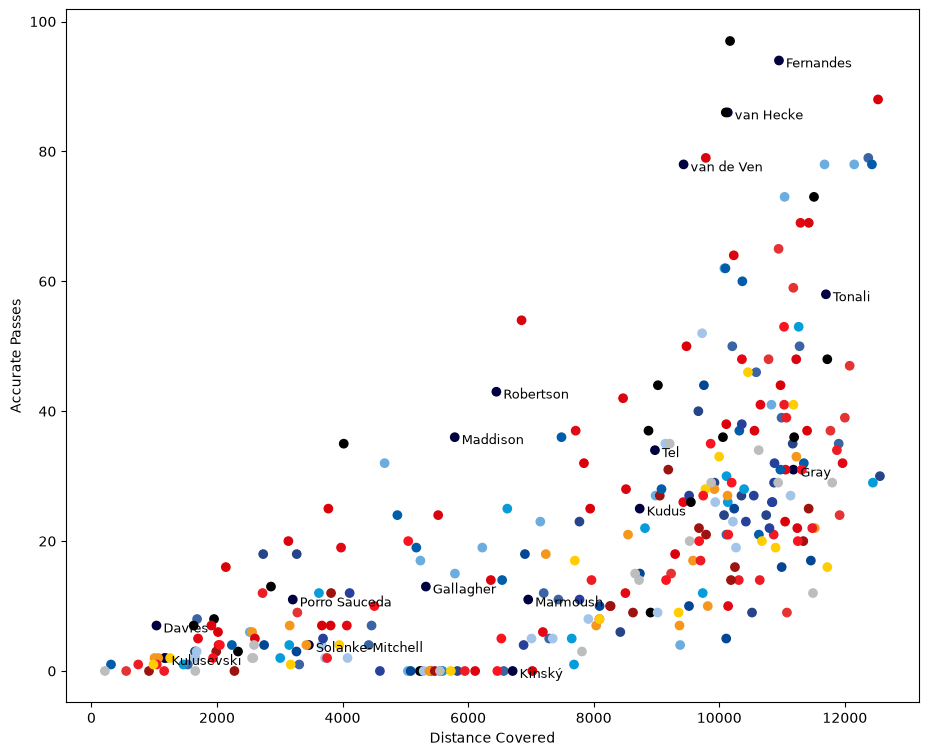

In [147]:
plt.figure(figsize=(11, 9))
plt.scatter(playermatchstats["distance_covered"],playermatchstats["accurate_passes"], c=playermatchstats["team_color"])
#plt.scatter(playermatchstats[(playermatchstats["short_name"] == "CHE") | (playermatchstats["short_name"] == "TOT")]["distance_covered"], playermatchstats[(playermatchstats["short_name"] == "CHE") | (playermatchstats["short_name"] == "TOT")]["accurate_passes"], c=playermatchstats[(playermatchstats["short_name"] == "CHE") | (playermatchstats["short_name"] == "TOT")]["team_color"])
for _, row in tot_players.iterrows():
    plt.annotate(
        row["player_name"], 
        xy=(row["distance_covered"], row["accurate_passes"]), 
        textcoords="offset points",                           
        xytext=(5, -5),                                        
        fontsize=9
    )
plt.xlabel("Distance Covered")
plt.ylabel("Accurate Passes")